<a href="https://colab.research.google.com/github/esranuraltinay/Kalp-Yetmezligi-Olum-Riski-Tahmini/blob/main/notebooks/01_baslangic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Kütüphaneler ve Tohum Sabitleme**

Bu hücrede gerekli kütüphaneleri içe aktarıp rastgelelik tohumu sabitlendi.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Tekrarlanabilirlik için tohumu sabitliyoruz. Veri analizi veya makine öğrenmesi modelini başka bilgisayarda çalıştırıldığında veri setinin eğitim/test olarak bölünmesini veya modelin başlangıç ağırlıklarının atanması gibi rastgele adımlarda sizinle birebir aynı souçları almasını sağlar.
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
print("Kütüphaneler yüklendi ve SEED sabitlendi.")

Kütüphaneler yüklendi ve SEED sabitlendi.


##  **Veri Yükleme**

Bu hücrede bilgisayardaki CSV dosyasını Colab ortamına yüklendi ve pandas ile okutuldu.

In [4]:
from google.colab import files
uploaded = files.upload()

dosya_adi = list(uploaded.keys())[0]
df = pd.read_csv(dosya_adi)
print("Veri başarıyla yüklendi!")

Saving heart_failure_clinical_records_dataset.csv to heart_failure_clinical_records_dataset (1).csv
Veri başarıyla yüklendi!


## **Veriyi Tanıma ve Yapısal Kontroller**

Verinin boyutuna, ilk satırlarına, sütun tiplerine ve eksik değer olup olmadığına bakılmıştır.

In [5]:
print("Veri Setinin Boyutu (Satır, Sütun):", df.shape)
display(df.head())

print("\nSütun İsimleri ve Tipleri:")
df.info()

print("\nEksik Değer Sayıları:")
print(df.isnull().sum())

Veri Setinin Boyutu (Satır, Sütun): (299, 13)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1



Sütun İsimleri ve Tipleri:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage

## **Hedef Değişken Dağılımı**
Bu hücrede ölüm durumunun (DEATH_EVENT) sınıfsal dağılımını görselleştirilmiştir.

/tmp/ipykernel_856/189067820.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='DEATH_EVENT', data=df, palette='Set2')


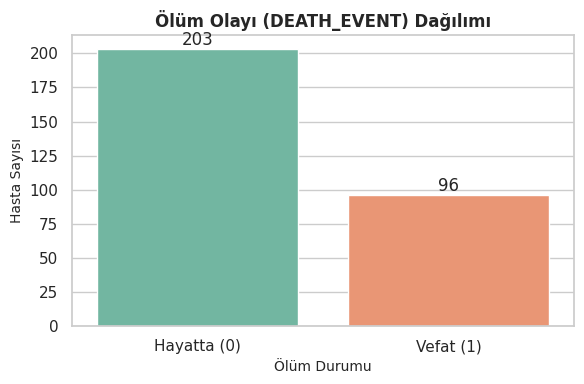

Sınıf Dağılımı ve Oranları (%):

DEATH_EVENT
0    203
1     96
Name: count, dtype: int64
------------------------------
DEATH_EVENT
0    67.892977
1    32.107023
Name: proportion, dtype: float64


In [17]:
plt.figure(figsize=(6, 4))

# hue parametresini kaldırıp sade bir countplot kullanıyoruz
ax = sns.countplot(x='DEATH_EVENT', data=df, palette='Set2')

plt.title('Ölüm Olayı (DEATH_EVENT) Dağılımı', fontsize=12, fontweight='bold')
plt.xlabel('Ölüm Durumu', fontsize=10)
plt.ylabel('Hasta Sayısı', fontsize=10)

# X ekseni etiketleri
plt.xticks([0, 1], ['Hayatta (0)', 'Vefat (1)'])

# TÜM barların üzerine (hem 0 hem 1 için) sayıları otomatik yazdırmak için döngü kullanıyoruz
for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

# Konsola sayı ve oranları yazdırma
print("Sınıf Dağılımı ve Oranları (%):\n")
print(df['DEATH_EVENT'].value_counts())
print("-" * 30)
print(df['DEATH_EVENT'].value_counts(normalize=True) * 100)

## **Yaş Dağılımı**

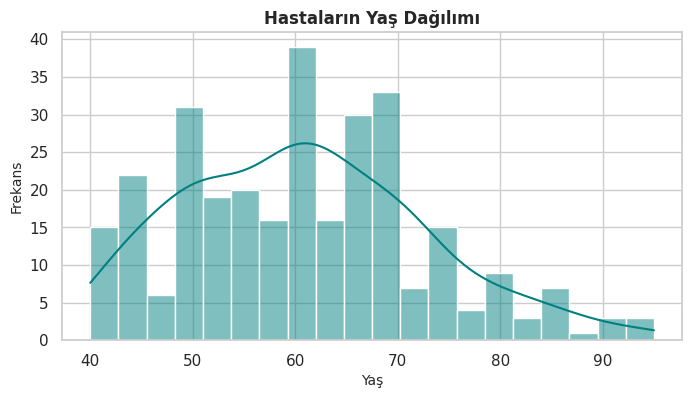

In [18]:
plt.figure(figsize=(8, 4))
sns.histplot(df['age'], bins=20, kde=True, color='teal')
plt.title('Hastaların Yaş Dağılımı', fontsize=12, fontweight='bold')
plt.xlabel('Yaş', fontsize=10)
plt.ylabel('Frekans', fontsize=10)
plt.show()